# 🚀 우주 발사체 제원 및 대기 환경 기반 발사 성공/실패 심층 특징값(Feature Signal) 시각화 분석
- **분석 데이터셋**:  (총 7,404건)
- **핵심 목표**: 발사 실패(Failure)를 유발하는 지배적 특징값(Feature) 및 임계값(Threshold) 식별
- **규칙**: 코드 셀 하나당 독립적인 고품질 시각화 그래프 1개 출력 (한글 깨짐 없음)

In [3]:
import os
import platform
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier

# 1. 경고 메시지 숨김 처리
warnings.filterwarnings('ignore')

# 2. 한글 폰트 설정 (macOS: AppleGothic)
if platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
elif platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
else:
    plt.rcParams['font.family'] = 'NanumGothic'

plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style="whitegrid", font=plt.rcParams['font.family'])

# 3. 데이터 로드 및 파생 피처 생성
df = pd.read_csv("./data/output/combined_rocket_weather_dataset.csv")
df["launch_time_utc"] = pd.to_datetime(df["launch_time_utc"])
df["year"] = df["launch_time_utc"].dt.year
df["month"] = df["launch_time_utc"].dt.month
df["hour"] = df["launch_time_utc"].dt.hour
df["status_label"] = df["launch_status"].map({1: "성공 (1)", 0: "실패 (0)"})

# 주요 파생 피처 (Feature Engineering)
# (1) 추력 대 중량비 (TWR)
df["twr"] = (df["liftoff_thrust_kn"] * 1000.0) / (df["total_mass_kg"] * 9.80665)
# (2) 돌풍 편차 (Gust Delta)
df["gust_delta"] = df["wind_gust"] - df["surface_wind_speed"]
# (3) Max Q 구간 복합 동압 시어 위험도
df["max_q_shear_risk"] = df["upper_air_wind_speed_10km"] * df["max_wind_shear"]

total = len(df)
succ = df["launch_status"].value_counts().get(1, 0)
fail = df["launch_status"].value_counts().get(0, 0)

print("=" * 55)
print(f"총 발사 데이터 수 : {total:,}건")
print(f"성공 건수 (1)   : {succ:,}건 ({succ / total * 100:.2f}%)")
print(f"실패 건수 (0)   : {fail:,}건 ({fail / total * 100:.2f}%)")
print("=" * 55)

총 발사 데이터 수 : 7,404건
성공 건수 (1)   : 6,897건 (93.15%)
실패 건수 (0)   : 507건 (6.85%)


### [그래프 1] 전체 발사 성공률 vs 실패율 도넛 차트

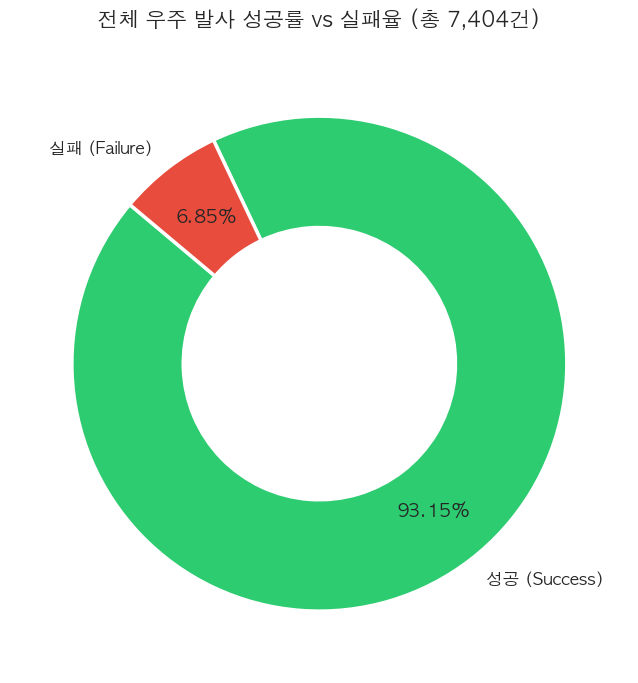

In [4]:
# 1. 성공률 vs 실패율 도넛 차트
plt.figure(figsize=(7, 7))
counts = [df["launch_status"].value_counts().get(1, 0), df["launch_status"].value_counts().get(0, 0)]
labels = ["성공 (Success)", "실패 (Failure)"]
colors = ["#2ecc71", "#e74c3c"]

wedges, texts, autotexts = plt.pie(
    counts, 
    labels=labels, 
    autopct="%1.2f%%", 
    startangle=140, 
    colors=colors,
    wedgeprops=dict(width=0.45, edgecolor="white", linewidth=2.5),
    pctdistance=0.75,
    textprops=dict(fontsize=12, weight="bold")
)
for at in autotexts: at.set_fontsize(13)

plt.title(f"전체 우주 발사 성공률 vs 실패율 (총 {len(df):,}건)", fontsize=15, weight="bold", pad=20)
plt.tight_layout()
plt.show()

### [그래프 2] 연도별(1957~현재) 발사 횟수 및 결과(성공/실패) 누적 막대그래프

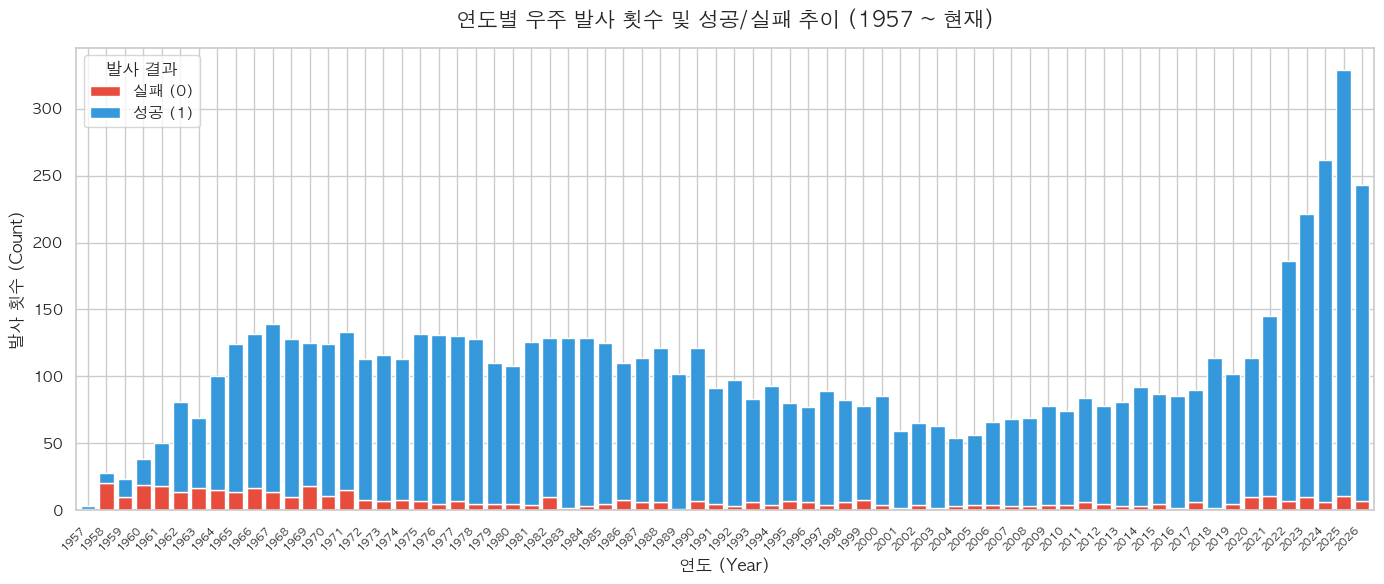

In [5]:
# 2. 연도별 발사 횟수 및 결과 추이
plt.figure(figsize=(14, 6))
yearly = df.groupby(["year", "launch_status"]).size().unstack(fill_value=0)
if 1 not in yearly.columns: yearly[1] = 0
if 0 not in yearly.columns: yearly[0] = 0
yearly = yearly[[0, 1]].rename(columns={1: "성공 (1)", 0: "실패 (0)"})

yearly.plot(kind="bar", stacked=True, figsize=(14, 6), color=["#e74c3c", "#3498db"], width=0.8, ax=plt.gca())
plt.title("연도별 우주 발사 횟수 및 성공/실패 추이 (1957 ~ 현재)", fontsize=15, weight="bold", pad=15)
plt.xlabel("연도 (Year)", fontsize=12)
plt.ylabel("발사 횟수 (Count)", fontsize=12)
plt.xticks(rotation=45, ha="right", fontsize=8)
plt.legend(title="발사 결과", loc="upper left", frameon=True)
plt.tight_layout()
plt.show()

### [그래프 3] 발사체 체급(Small / Medium / Heavy)별 발사 성공률

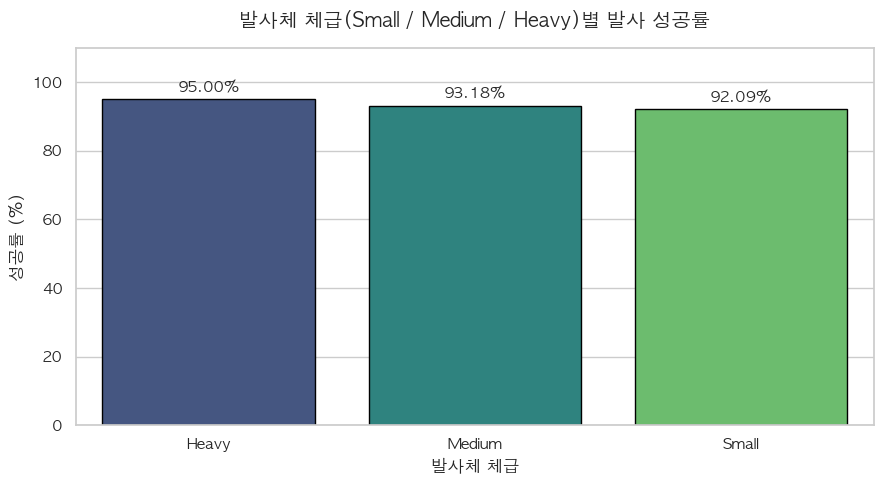

In [6]:
# 3. 체급별 발사 성공률 비교
plt.figure(figsize=(9, 5))
type_stat = df.groupby("rocket_type")["launch_status"].agg(["count", "mean"]).reset_index()
type_stat["mean"] = type_stat["mean"] * 100
type_stat = type_stat.sort_values(by="mean", ascending=False)

bars = sns.barplot(data=type_stat, x="rocket_type", y="mean", hue="rocket_type", palette="viridis", legend=False, edgecolor="black")
for bar in bars.patches:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2.0, yval + 1.2, f"{yval:.2f}%", ha="center", va="bottom", fontsize=11, weight="bold")

plt.ylim(0, 110)
plt.title("발사체 체급(Small / Medium / Heavy)별 발사 성공률", fontsize=14, weight="bold", pad=15)
plt.xlabel("발사체 체급", fontsize=12)
plt.ylabel("성공률 (%)", fontsize=12)
plt.tight_layout()
plt.show()

### [그래프 4] 지상 풍속(Surface Wind Speed) 구간별 발사 실패율 추이 (핵심 특징)

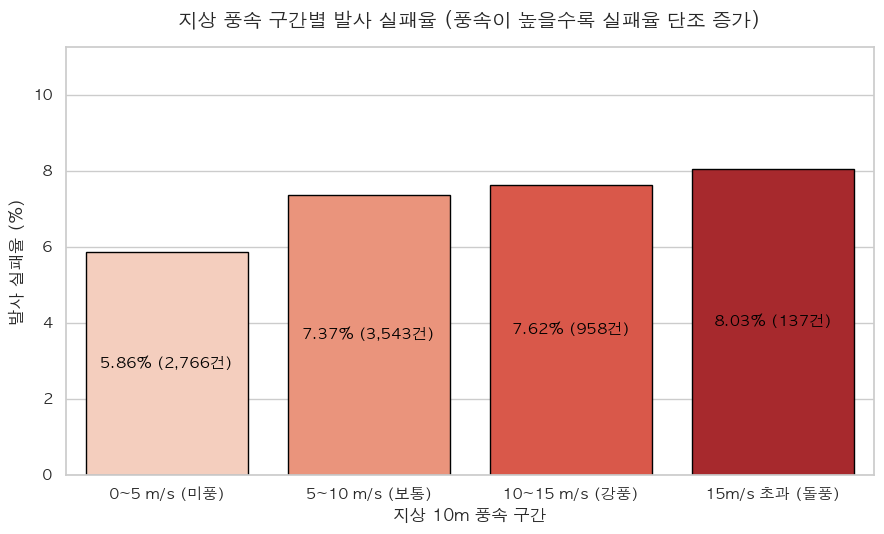

In [7]:
# 4. 지상 풍속 구간별 발사 실패율 (풍속 증가 시 실패율 급증 확인)
plt.figure(figsize=(9, 5.5))
df["wind_bin"] = pd.cut(df["surface_wind_speed"], bins=[0, 5, 10, 15, 30], labels=["0~5 m/s (미풍)", "5~10 m/s (보통)", "10~15 m/s (강풍)", "15m/s 초과 (돌풍)"])
wind_fail = df.groupby("wind_bin", observed=False)["launch_status"].agg(
    total="count",
    fail_rate=lambda x: (1.0 - x.mean()) * 100.0
).reset_index()

ax = sns.barplot(data=wind_fail, x="wind_bin", y="fail_rate", palette="Reds", edgecolor="black")
for p, total in zip(ax.patches, wind_fail["total"]):
    h = p.get_height()
    ax.annotate(f"{h:.2f}% ({total:,}건)", (p.get_x() + p.get_width() / 2., h / 2), ha="center", va="center", color="black", weight="bold", fontsize=11)

plt.title("지상 풍속 구간별 발사 실패율 (풍속이 높을수록 실패율 단조 증가)", fontsize=14, weight="bold", pad=15)
plt.xlabel("지상 10m 풍속 구간", fontsize=12)
plt.ylabel("발사 실패율 (%)", fontsize=12)
plt.ylim(0, wind_fail["fail_rate"].max() * 1.4)
plt.tight_layout()
plt.show()

### [그래프 5] 머신러닝(Random Forest) 기반 기상 및 제원 변수 중요도 (Feature Importance)

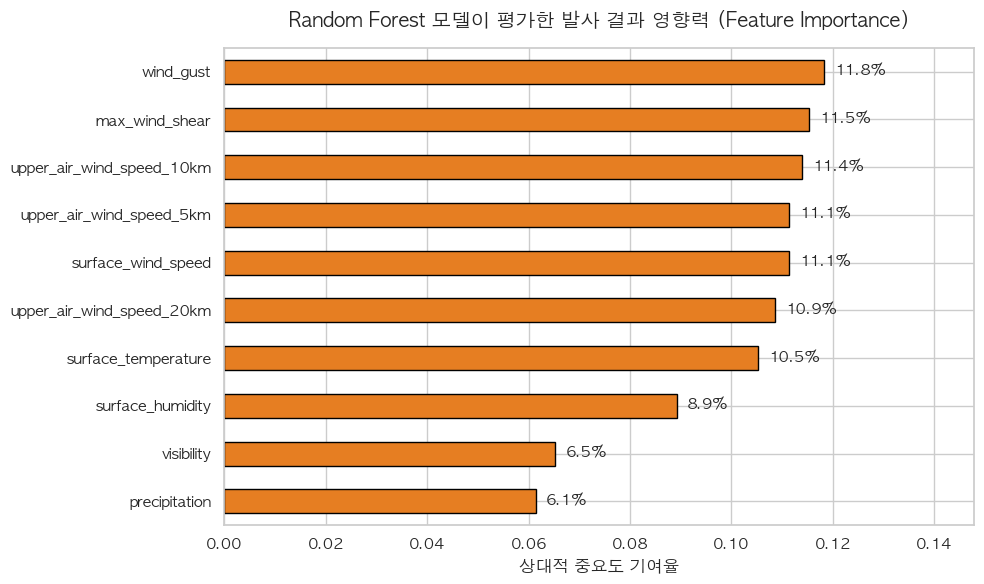

In [8]:
# 5. 머신러닝 피처 중요도 분석 (어떤 변수가 발사 결과를 가장 잘 가르는가?)
features = [
    "upper_air_wind_speed_10km", "wind_gust", "surface_wind_speed", 
    "upper_air_wind_speed_5km", "max_wind_shear", "surface_temperature", 
    "upper_air_wind_speed_20km", "surface_humidity", "visibility", "precipitation"
]

X = df[features].fillna(df[features].median())
y = df["launch_status"]

rf = RandomForestClassifier(n_estimators=100, random_state=42, class_weight="balanced")
rf.fit(X, y)

feat_imp = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
feat_imp.plot(kind="barh", color="#e67e22", edgecolor="black", ax=plt.gca())
for i, v in enumerate(feat_imp):
    plt.text(v + 0.002, i, f"{v*100:.1f}%", va="center", fontsize=11, weight="bold")

plt.title("Random Forest 모델이 평가한 발사 결과 영향력 (Feature Importance)", fontsize=14, weight="bold", pad=15)
plt.xlabel("상대적 중요도 기여율", fontsize=12)
plt.xlim(0, feat_imp.max() * 1.25)
plt.tight_layout()
plt.show()

### [그래프 6] 상공 10km 풍속(Max Q) vs 지상 돌풍(Wind Gust) 실패 발사 집중 영역 (2D KDE)

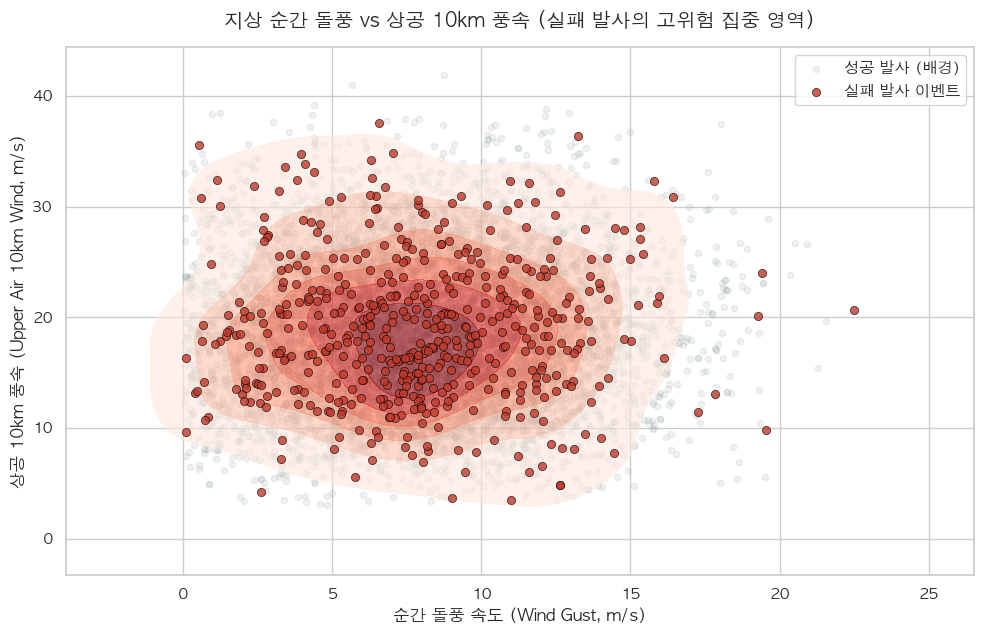

In [9]:
# 6. 상위 2대 중요 변수 (10km 풍속 vs 돌풍) 실패 집중 영역 시각화
plt.figure(figsize=(10, 6.5))
fails = df[df["launch_status"] == 0]
succs = df[df["launch_status"] == 1]

# 전체 성공 배경 산점도
plt.scatter(succs["wind_gust"], succs["upper_air_wind_speed_10km"], color="#95a5a6", alpha=0.15, s=20, label="성공 발사 (배경)")

# 실패 발사의 2D 밀도 등고선 (KDE Contour)
sns.kdeplot(
    data=fails, 
    x="wind_gust", 
    y="upper_air_wind_speed_10km", 
    cmap="Reds", 
    fill=True, 
    alpha=0.6,
    levels=7,
    thresh=0.05
)

plt.scatter(fails["wind_gust"], fails["upper_air_wind_speed_10km"], color="#c0392b", alpha=0.8, s=35, edgecolor="black", linewidth=0.5, label="실패 발사 이벤트")

plt.title("지상 순간 돌풍 vs 상공 10km 풍속 (실패 발사의 고위험 집중 영역)", fontsize=14, weight="bold", pad=15)
plt.xlabel("순간 돌풍 속도 (Wind Gust, m/s)", fontsize=12)
plt.ylabel("상공 10km 풍속 (Upper Air 10km Wind, m/s)", fontsize=12)
plt.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.show()

### [그래프 7] 연직 윈드 시어(Max Wind Shear) 분위수별 실패율 변화

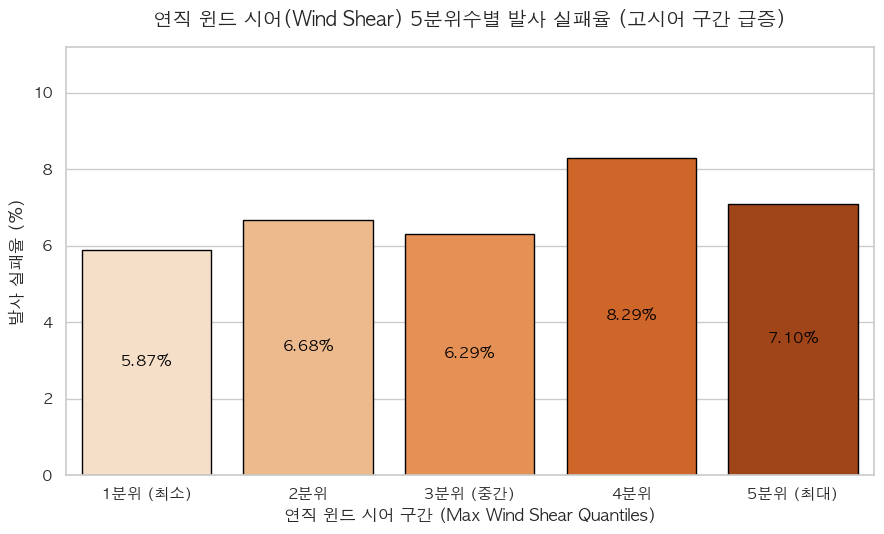

In [10]:
# 7. 연직 윈드 시어 분위수별 실패율 분석
plt.figure(figsize=(9, 5.5))
df["shear_bin"] = pd.qcut(df["max_wind_shear"], q=5, labels=["1분위 (최소)", "2분위", "3분위 (중간)", "4분위", "5분위 (최대)"])
shear_fail = df.groupby("shear_bin", observed=False)["launch_status"].agg(
    total="count",
    fail_rate=lambda x: (1.0 - x.mean()) * 100.0
).reset_index()

ax = sns.barplot(data=shear_fail, x="shear_bin", y="fail_rate", palette="Oranges", edgecolor="black")
for p in ax.patches:
    h = p.get_height()
    ax.annotate(f"{h:.2f}%", (p.get_x() + p.get_width() / 2., h / 2), ha="center", va="center", color="black", weight="bold", fontsize=11)

plt.title("연직 윈드 시어(Wind Shear) 5분위수별 발사 실패율 (고시어 구간 급증)", fontsize=14, weight="bold", pad=15)
plt.xlabel("연직 윈드 시어 구간 (Max Wind Shear Quantiles)", fontsize=12)
plt.ylabel("발사 실패율 (%)", fontsize=12)
plt.ylim(0, shear_fail["fail_rate"].max() * 1.35)
plt.tight_layout()
plt.show()

### [그래프 8] 복합 동압-시어 위험 지수 (Max Q Dynamic Risk = 10km 풍속 × 연직 시어) 분포

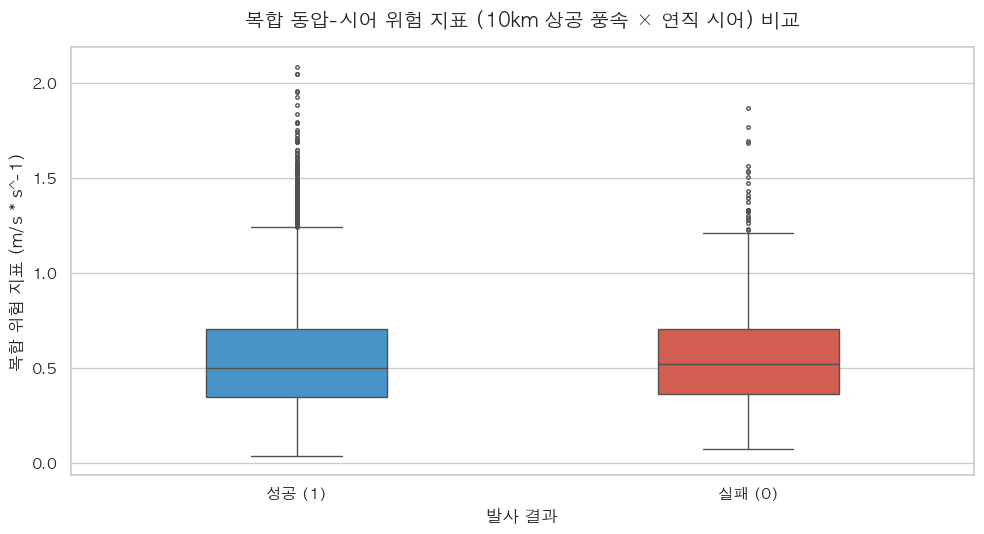

In [11]:
# 8. 복합 동압-시어 위험도(Max Q Risk)에 따른 성공/실패 분포
plt.figure(figsize=(10, 5.5))
sns.boxplot(
    data=df, 
    x="status_label", 
    y="max_q_shear_risk", 
    hue="status_label",
    palette={"성공 (1)": "#3498db", "실패 (0)": "#e74c3c"}, 
    legend=False,
    width=0.4,
    fliersize=2.5
)

plt.title("복합 동압-시어 위험 지표 (10km 상공 풍속 × 연직 시어) 비교", fontsize=14, weight="bold", pad=15)
plt.xlabel("발사 결과", fontsize=12)
plt.ylabel("복합 위험 지표 (m/s * s^-1)", fontsize=12)
plt.tight_layout()
plt.show()

### [그래프 9] 발사체 추력 대 중량비(TWR) 구간별 실패율 비교 (제원 특징값)

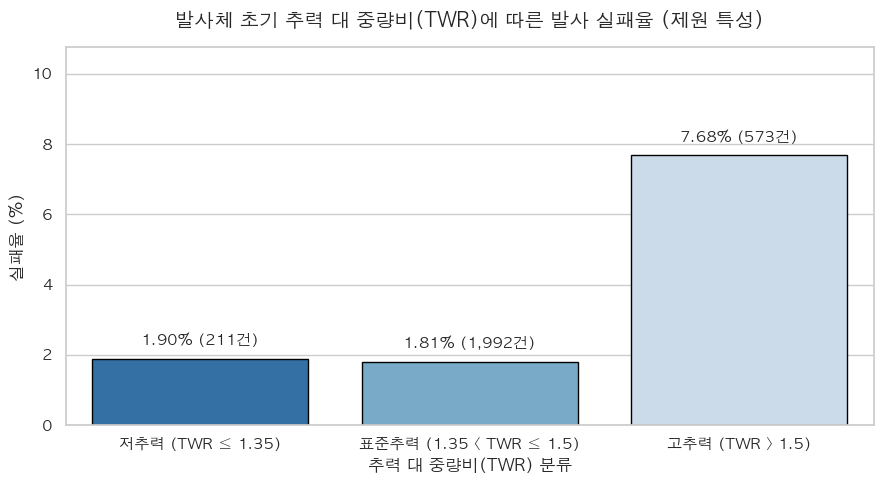

In [12]:
# 9. 추력 대 중량비(TWR)에 따른 실패율 비교
twr_df = df.dropna(subset=["twr"])
twr_df["twr_category"] = pd.cut(
    twr_df["twr"], 
    bins=[0, 1.35, 1.5, 3.0], 
    labels=["저추력 (TWR ≤ 1.35)", "표준추력 (1.35 < TWR ≤ 1.5)", "고추력 (TWR > 1.5)"]
)

twr_stat = twr_df.groupby("twr_category", observed=False)["launch_status"].agg(
    total="count",
    fail_rate=lambda x: (1.0 - x.mean()) * 100.0
).reset_index()

plt.figure(figsize=(9, 5))
ax = sns.barplot(data=twr_stat, x="twr_category", y="fail_rate", palette="Blues_r", edgecolor="black")
for p, total in zip(ax.patches, twr_stat["total"]):
    h = p.get_height()
    ax.annotate(f"{h:.2f}% ({total:,}건)", (p.get_x() + p.get_width() / 2., h + 0.3), ha="center", va="bottom", weight="bold", fontsize=11)

plt.title("발사체 초기 추력 대 중량비(TWR)에 따른 발사 실패율 (제원 특성)", fontsize=14, weight="bold", pad=15)
plt.xlabel("추력 대 중량비(TWR) 분류", fontsize=12)
plt.ylabel("실패율 (%)", fontsize=12)
plt.ylim(0, twr_stat["fail_rate"].max() * 1.4)
plt.tight_layout()
plt.show()

### [그래프 10] 강수 유무(Precipitation > 0.1 mm/hr)에 따른 발사 실패율

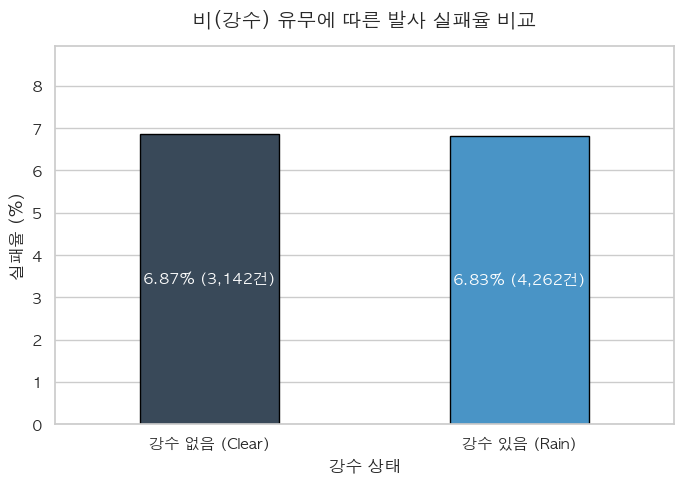

In [13]:
# 10. 강수 유무에 따른 실패율 비교
df["rain_status"] = np.where(df["precipitation"] > 0.1, "강수 있음 (Rain)", "강수 없음 (Clear)")
rain_stat = df.groupby("rain_status")["launch_status"].agg(
    total="count",
    fail_rate=lambda x: (1.0 - x.mean()) * 100.0
).reset_index()

plt.figure(figsize=(7, 5))
ax = sns.barplot(data=rain_stat, x="rain_status", y="fail_rate", palette=["#34495e", "#3498db"], edgecolor="black", width=0.45)
for p, tot in zip(ax.patches, rain_stat["total"]):
    h = p.get_height()
    ax.annotate(f"{h:.2f}% ({tot:,}건)", (p.get_x() + p.get_width() / 2., h / 2), ha="center", va="center", color="white", weight="bold", fontsize=11)

plt.title("비(강수) 유무에 따른 발사 실패율 비교", fontsize=14, weight="bold", pad=15)
plt.xlabel("강수 상태", fontsize=12)
plt.ylabel("실패율 (%)", fontsize=12)
plt.ylim(0, rain_stat["fail_rate"].max() * 1.3)
plt.tight_layout()
plt.show()

### [그래프 11] 발사 시각(주간 vs 야간)에 따른 성공/실패 분포

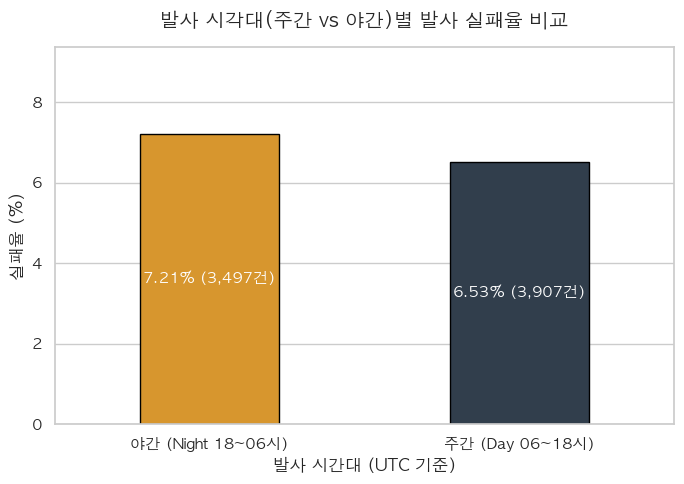

In [14]:
# 11. 주간(06~18시) vs 야간(18~06시) 발사 실패율 비교
df["time_of_day"] = np.where((df["hour"] >= 6) & (df["hour"] < 18), "주간 (Day 06~18시)", "야간 (Night 18~06시)")
tod_stat = df.groupby("time_of_day")["launch_status"].agg(
    total="count",
    fail_rate=lambda x: (1.0 - x.mean()) * 100.0
).reset_index()

plt.figure(figsize=(7, 5))
ax = sns.barplot(data=tod_stat, x="time_of_day", y="fail_rate", palette=["#f39c12", "#2c3e50"], edgecolor="black", width=0.45)
for p, tot in zip(ax.patches, tod_stat["total"]):
    h = p.get_height()
    ax.annotate(f"{h:.2f}% ({tot:,}건)", (p.get_x() + p.get_width() / 2., h / 2), ha="center", va="center", color="white", weight="bold", fontsize=11)

plt.title("발사 시각대(주간 vs 야간)별 발사 실패율 비교", fontsize=14, weight="bold", pad=15)
plt.xlabel("발사 시간대 (UTC 기준)", fontsize=12)
plt.ylabel("실패율 (%)", fontsize=12)
plt.ylim(0, tod_stat["fail_rate"].max() * 1.3)
plt.tight_layout()
plt.show()

### [그래프 12] 월별(1월~12월) 평균 발사 실패율 계절성(Seasonality) 추이

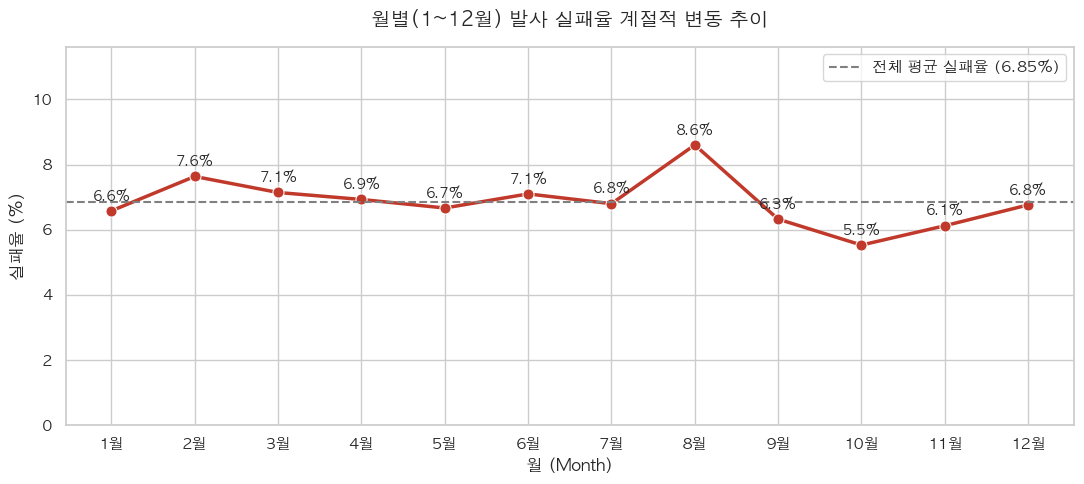

In [15]:
# 12. 월별 발사 실패율 계절성 변화
plt.figure(figsize=(11, 5))
monthly_stat = df.groupby("month")["launch_status"].agg(
    total="count",
    fail_rate=lambda x: (1.0 - x.mean()) * 100.0
).reset_index()

sns.lineplot(data=monthly_stat, x="month", y="fail_rate", marker="o", markersize=8, color="#c0392b", linewidth=2.5)
plt.axhline(y=df["launch_status"].agg(lambda x: (1.0 - x.mean()) * 100.0), color="gray", linestyle="--", label=f"전체 평균 실패율 ({6.85:.2f}%)")

for _, row in monthly_stat.iterrows():
    plt.text(row["month"], row["fail_rate"] + 0.3, f"{row['fail_rate']:.1f}%", ha="center", fontsize=10, weight="bold")

plt.title("월별(1~12월) 발사 실패율 계절적 변동 추이", fontsize=14, weight="bold", pad=15)
plt.xlabel("월 (Month)", fontsize=12)
plt.ylabel("실패율 (%)", fontsize=12)
plt.xticks(range(1, 13), [f"{m}월" for m in range(1, 13)])
plt.legend(loc="upper right", frameon=True)
plt.ylim(0, monthly_stat["fail_rate"].max() * 1.35)
plt.tight_layout()
plt.show()

### [그래프 13] 발사체 제원 및 기상 피처 상관관계 히트맵 (Correlation Matrix)

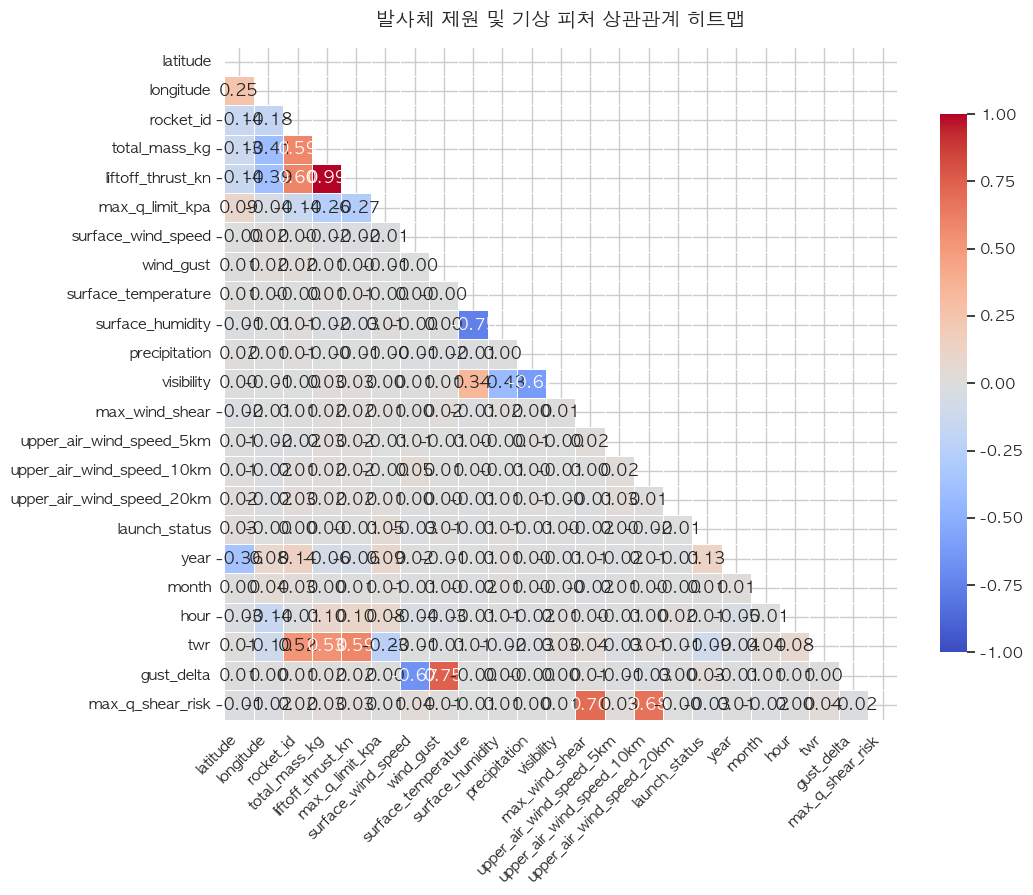

In [16]:
# 13. 수치형 피처 상관관계 행렬
numeric_df = df.select_dtypes(include=[np.number])
valid_cols = [col for col in numeric_df.columns if numeric_df[col].nunique() > 1]
corr_matrix = numeric_df[valid_cols].corr(method="pearson")

plt.figure(figsize=(11, 9))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix, 
    mask=mask,
    annot=True, 
    fmt=".2f", 
    cmap="coolwarm", 
    vmin=-1, 
    vmax=1, 
    linewidths=0.5,
    square=True,
    cbar_kws={"shrink": 0.8}
)

plt.title("발사체 제원 및 기상 피처 상관관계 히트맵", fontsize=14, weight="bold", pad=15)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### [그래프 14] 상공 고도별(5km, 10km, 20km) 평균 풍속 프로파일

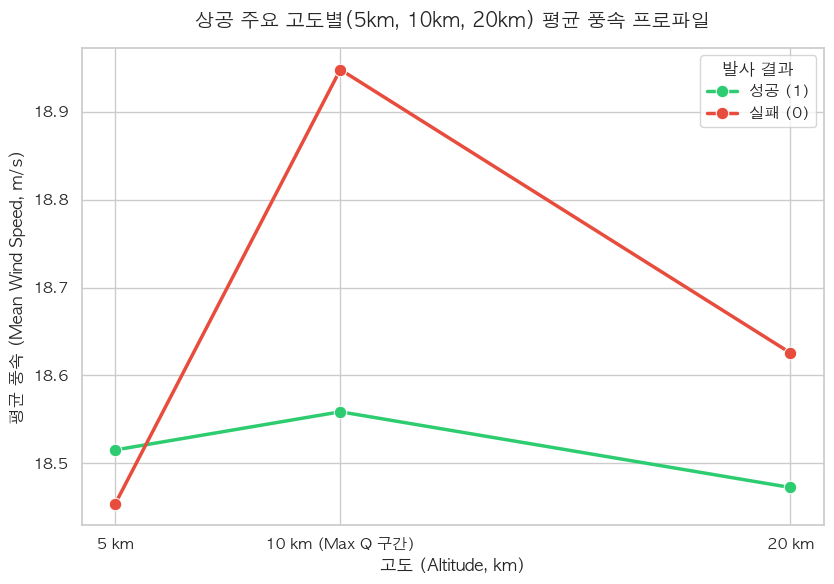

In [17]:
# 14. 고도별 평균 풍속 프로파일 비교
wind_cols = ["upper_air_wind_speed_5km", "upper_air_wind_speed_10km", "upper_air_wind_speed_20km"]
mean_winds = df.groupby("status_label")[wind_cols].mean().reset_index()

melted = pd.melt(mean_winds, id_vars=["status_label"], value_vars=wind_cols, var_name="altitude", value_name="wind_speed")
melted["altitude_km"] = melted["altitude"].map({
    "upper_air_wind_speed_5km": 5,
    "upper_air_wind_speed_10km": 10,
    "upper_air_wind_speed_20km": 20
})

plt.figure(figsize=(8.5, 6))
sns.lineplot(
    data=melted, 
    x="altitude_km", 
    y="wind_speed", 
    hue="status_label", 
    marker="o", 
    markersize=9, 
    linewidth=2.5,
    palette={"성공 (1)": "#2ecc71", "실패 (0)": "#e74c3c"}
)

plt.title("상공 주요 고도별(5km, 10km, 20km) 평균 풍속 프로파일", fontsize=14, weight="bold", pad=15)
plt.xlabel("고도 (Altitude, km)", fontsize=12)
plt.ylabel("평균 풍속 (Mean Wind Speed, m/s)", fontsize=12)
plt.xticks([5, 10, 20], ["5 km", "10 km (Max Q 구간)", "20 km"])
plt.legend(title="발사 결과", frameon=True)
plt.tight_layout()
plt.show()

### [그래프 15] 전 세계 발사 기지별 발사 횟수 및 성공률 지리적 분포

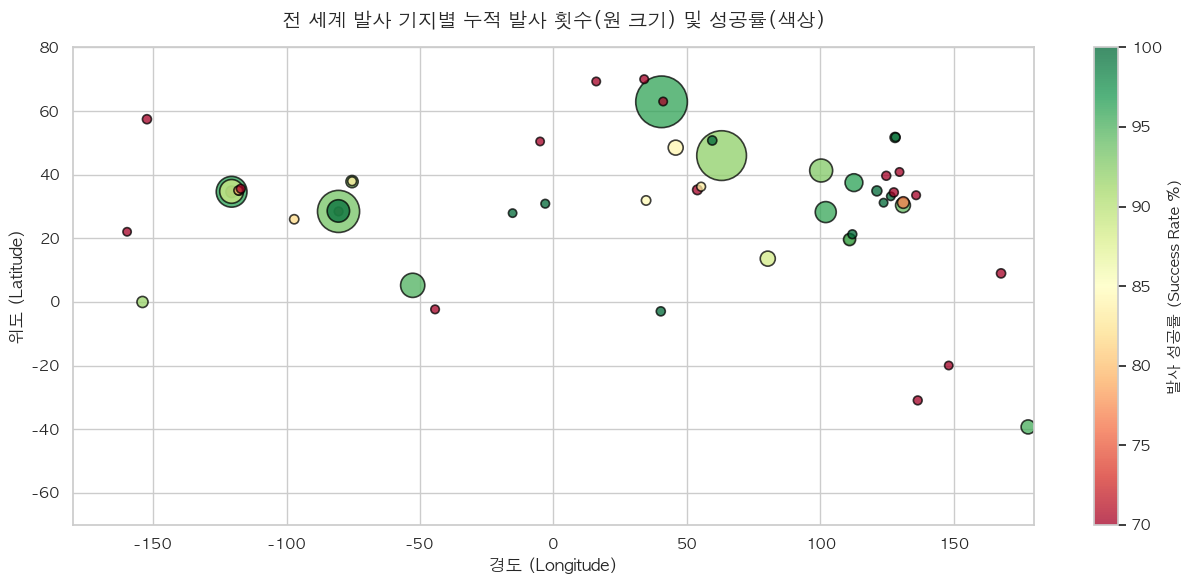

In [18]:
# 15. 발사 기지별 발사 횟수 및 성공률 공간 분포
plt.figure(figsize=(13, 6))
site_agg = df.groupby(["latitude", "longitude"]).agg(
    total_launches=("launch_status", "count"),
    success_rate=("launch_status", "mean")
).reset_index()

scatter = plt.scatter(
    site_agg["longitude"], 
    site_agg["latitude"], 
    s=site_agg["total_launches"] * 0.8 + 35, 
    c=site_agg["success_rate"] * 100, 
    cmap="RdYlGn", 
    alpha=0.75, 
    edgecolors="black", 
    linewidth=1.2,
    vmin=70, 
    vmax=100
)

cbar = plt.colorbar(scatter)
cbar.set_label("발사 성공률 (Success Rate %)", fontsize=11)

plt.title("전 세계 발사 기지별 누적 발사 횟수(원 크기) 및 성공률(색상)", fontsize=14, weight="bold", pad=15)
plt.xlabel("경도 (Longitude)", fontsize=12)
plt.ylabel("위도 (Latitude)", fontsize=12)
plt.xlim(-180, 180)
plt.ylim(-70, 80)
plt.tight_layout()
plt.show()

In [19]:
%pip install folium


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [20]:
# 발사 기지별 발사 횟수 및 성공률 지도 시각화
import numpy as np
import folium
from branca.colormap import LinearColormap

site_agg = (
    df.groupby(["latitude", "longitude"], as_index=False)
      .agg(
          total_launches=("launch_status", "count"),
          success_rate=("launch_status", "mean")
      )
      .dropna(subset=["latitude", "longitude"])
)

# 성공률을 퍼센트로 변환
site_agg["success_rate_pct"] = site_agg["success_rate"] * 100

# 지도 중심 설정
center = [
    site_agg["latitude"].mean(),
    site_agg["longitude"].mean()
]

launch_map = folium.Map(
    location=center,
    zoom_start=2,
    tiles="CartoDB positron"
)

# 성공률 색상 범례
color_scale = LinearColormap(
    colors=["#d73027", "#fee08b", "#1a9850"],
    vmin=0,
    vmax=100,
    caption="발사 성공률 (%)"
)
color_scale.add_to(launch_map)

# 원 크기 범위
min_radius = 6
max_radius = 24
max_launches = max(site_agg["total_launches"].max(), 1)

for row in site_agg.itertuples(index=False):
    # 발사 횟수가 많을수록 원이 커지도록 설정
    radius = (
        min_radius
        + (max_radius - min_radius)
        * np.sqrt(row.total_launches / max_launches)
    )

    folium.CircleMarker(
        location=[row.latitude, row.longitude],
        radius=float(radius),
        color="#333333",
        weight=1,
        fill=True,
        fill_color=color_scale(float(row.success_rate_pct)),
        fill_opacity=0.8,
        tooltip=(
            f"발사 횟수: {row.total_launches:,}회 | "
            f"성공률: {row.success_rate_pct:.1f}%"
        ),
        popup=folium.Popup(
            f"""
            <b>발사 기지</b><br>
            위도: {row.latitude:.4f}<br>
            경도: {row.longitude:.4f}<br>
            발사 횟수: {row.total_launches:,}회<br>
            성공률: {row.success_rate_pct:.1f}%
            """,
            max_width=250
        )
    ).add_to(launch_map)

# 모든 발사 기지가 화면에 들어오도록 범위 자동 조정
if len(site_agg) > 1:
    launch_map.fit_bounds([
        [
            site_agg["latitude"].min(),
            site_agg["longitude"].min()
        ],
        [
            site_agg["latitude"].max(),
            site_agg["longitude"].max()
        ]
    ])

launch_map